# Peso & Pulso

## Exploración de datos económicos colombianos, 2015–2025

La apreciación del peso corresponde a una caída de COP por USD. La exploración compara variaciones y conserva el PIB en frecuencia trimestral. Las asociaciones no identifican causalidad.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from peso_pulso.io import read_frame

root = Path.cwd()
if not (root / "config/sources.json").exists():
    root = root.parent
monthly = read_frame(root, "monthly")
main = monthly[monthly.is_main_sample == 1].copy()
quarterly = read_frame(root, "quarterly").query("is_main_sample == 1")
main[["trm_cop_usd", "inflation_yoy_pct", "exports_yoy_pct", "imports_yoy_pct", "brent_yoy_pct"]].describe().round(2)

,trm_cop_usd,inflation_yoy_pct,exports_yoy_pct,imports_yoy_pct,brent_yoy_pct
count,132.00,132.00,132.00,132.00,132.00
mean,3556.29,5.76,2.56,2.98,4.93
std,594.70,3.03,26.59,21.96,44.85
min,2397.26,1.49,-51.74,-40.80,-74.20
25%,3000.46,3.63,-13.45,-12.72,-22.20
50%,3631.77,4.98,-0.42,0.93,-3.41
75%,4000.84,7.39,15.45,12.00,22.02
max,4926.66,13.34,83.46,69.23,252.62


## Cobertura y calidad

El corte principal contiene 132 meses y 44 trimestres. Septiembre de 2026 carece de comercio exterior dentro del corte y permanece fuera de la muestra principal.

In [2]:
quality = json.loads((root / "reports/data_quality.json").read_text(encoding="utf-8"))
pd.DataFrame([quality])

,status,monthly_observations,quarterly_observations,trm_calendar_days,duplicate_dates,missing_main_sample,trade_balance_max_error_usd_m,monthly_coverage_end,common_monthly_end,quarterly_coverage_end,imputation
0,passed,132,44,4656,0,0,4.820322e-11,2026-09-01,2026-08-01,2026-04-01,none


In [3]:
fields = ["trm_yoy_pct", "inflation_yoy_pct", "exports_yoy_pct", "imports_yoy_pct", "brent_yoy_pct"]
main[fields].corr().round(3)

,trm_yoy_pct,inflation_yoy_pct,exports_yoy_pct,imports_yoy_pct,brent_yoy_pct
trm_yoy_pct,1.000,0.072,-0.466,-0.308,-0.473
inflation_yoy_pct,0.072,1.000,0.031,-0.131,-0.082
exports_yoy_pct,-0.466,0.031,1.000,0.826,0.840
imports_yoy_pct,-0.308,-0.131,0.826,1.000,0.770
brent_yoy_pct,-0.473,-0.082,0.840,0.770,1.000


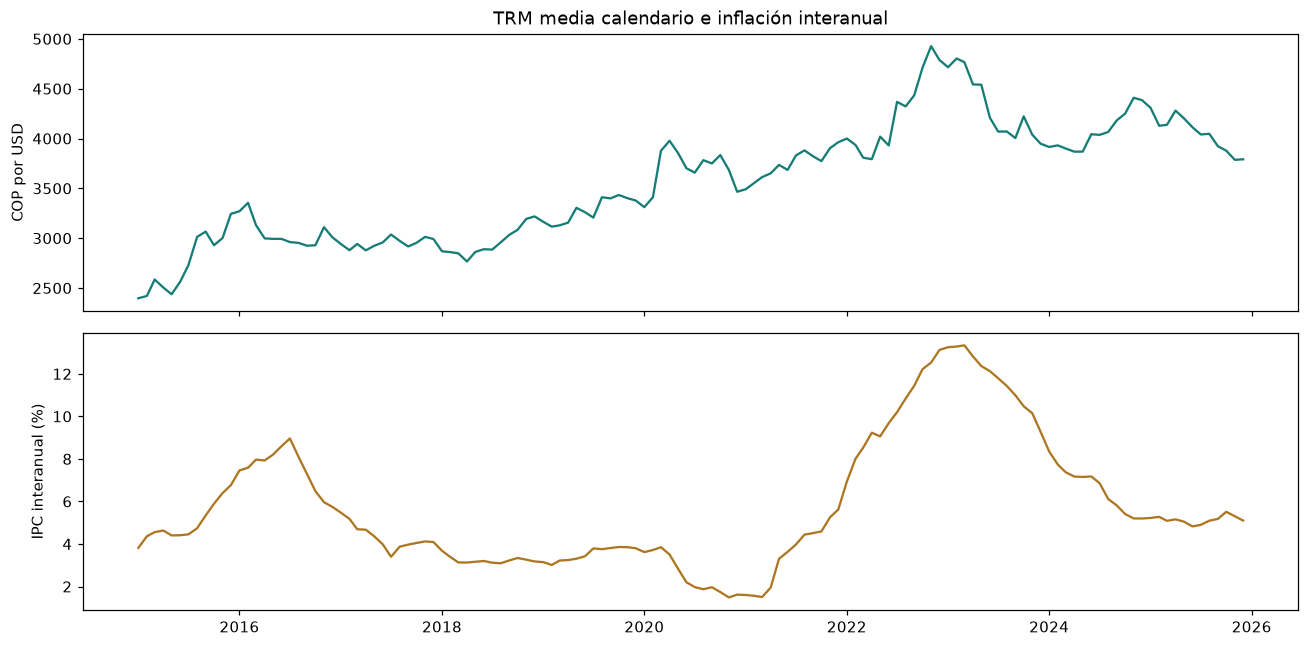

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(main.date, main.trm_cop_usd, color="#167D76")
axes[0].set_ylabel("COP por USD")
axes[0].set_title("TRM media calendario e inflación interanual")
axes[1].plot(main.date, main.inflation_yoy_pct, color="#AD7722")
axes[1].set_ylabel("IPC interanual (%)")
fig.tight_layout()

## Sensibilidad temporal

Los rezagos relacionan el dólar de meses anteriores con el indicador actual. Cada combinación conserva su tamaño efectivo de muestra.

In [5]:
correlations = pd.read_csv(root / "reports/correlations.csv")
correlations[correlations.outcome == "inflation_yoy_pct"].round(3)

,outcome,fx_lag_months,sample,n,pearson_r,spearman_r
0,inflation_yoy_pct,0,2015–2025,132,0.072,0.053
1,inflation_yoy_pct,0,Sin 2020–2021,108,0.071,0.077
2,inflation_yoy_pct,1,2015–2025,131,0.121,0.094
3,inflation_yoy_pct,1,Sin 2020–2021,107,0.138,0.156
4,inflation_yoy_pct,3,2015–2025,129,0.198,0.159
5,inflation_yoy_pct,3,Sin 2020–2021,105,0.249,0.280
6,inflation_yoy_pct,6,2015–2025,126,0.273,0.239
7,inflation_yoy_pct,6,Sin 2020–2021,102,0.360,0.428
8,inflation_yoy_pct,12,2015–2025,120,0.195,0.209
9,inflation_yoy_pct,12,Sin 2020–2021,96,0.296,0.426


In [6]:
pd.read_csv(root / "reports/gdp_correlations.csv").round(3)

,x,y,sample,n,pearson_r,spearman_r
0,trm_yoy_pct,gdp_yoy_pct,2015–2025,44,-0.062,0.239
1,trm_yoy_pct,gdp_yoy_pct,Sin 2020–2021,36,0.245,0.524
2,trm_qoq_pct,gdp_qoq_sa_pct,2015–2025,44,-0.221,-0.022
3,trm_qoq_pct,gdp_qoq_sa_pct,Sin 2020–2021,36,0.228,0.206


## Modelo exploratorio y límites

Los coeficientes usan inflación mensual y errores HAC(12). La suma de rezagos no es un efecto causal ni un multiplicador de largo plazo. Los diagnósticos de estacionariedad permanecen visibles en el informe.

In [7]:
coefficients = pd.read_csv(root / "reports/model_coefficients.csv")
coefficients[coefficients.term.str.startswith("fx_mom_lag")].round(4)

,model,term,coefficient,std_error_hac,ci_lower_95,ci_upper_95,p_value,n
1,full,fx_mom_lag1,0.0145,0.0063,0.0022,0.0268,0.0210,132
2,full,fx_mom_lag2,0.0015,0.0046,-0.0075,0.0106,0.7416,132
3,full,fx_mom_lag3,-0.0007,0.0043,-0.0091,0.0077,0.8697,132


## Hallazgo

La correlación interanual dólar–PIB es −0,06 en la muestra completa y +0,24 sin 2020–2021. El comercio y el petróleo muestran relaciones negativas con la depreciación interanual. Las diferencias de frecuencia, valoración y periodo son decisivas para interpretar estas cifras. Fuentes y decisiones metodológicas: `docs/FUENTES.md` y `docs/METODOLOGIA.md`.